In [13]:
import pandas as pd
import random

# Template words to construct synthetic reviews
positive_templates = [
    "This {} was absolutely amazing, highly recommend!",
    "Loved the {}, the acting and story were brilliant.",
    "A masterpiece of a {}, genuinely enjoyed every second.",
    "Great {}, fantastic visuals and amazing cast!",
    "One of the best {}s I have seen in a long time."
]

negative_templates = [
    "This {} was terrible, a complete waste of time.",
    "Awful {} with boring characters and a predictable plot.",
    "I hated the {}, the acting was extremely poor.",
    "Worst {} ever. It fell flat and was way too long.",
    "Extremely disappointing {}, nothing went right."
]

neutral_templates = [
    "The {} was okay, nothing special but not bad either.",
    "Decent {}, average acting and a standard storyline.",
    "It was a tolerable {}, fine to watch once.",
    "Some parts of the {} were good, others were slow.",
    "An average {} overall, okay for a lazy afternoon."
]

subjects = ["movie", "film", "show", "series", "story"]

# Generate 500 samples
synthetic_data = []
for _ in range(500):
    sentiment = random.choice(["positive", "negative", "neutral"])
    subject = random.choice(subjects)

    if sentiment == "positive":
        review = random.choice(positive_templates).format(subject)
    elif sentiment == "negative":
        review = random.choice(negative_templates).format(subject)
    else:
        review = random.choice(neutral_templates).format(subject)

    synthetic_data.append({"review": review, "sentiment": sentiment})

# Overwrite the reviews.csv file with 500 records
df_large = pd.DataFrame(synthetic_data)
df_large.to_csv("reviews.csv", index=False)
print(f"Success! Created a new 'reviews.csv' with {len(df_large)} synthetic reviews.")
print("You can now re-run the classification cell above to train your model with the larger dataset.")

Success! Created a new 'reviews.csv' with 500 synthetic reviews.
You can now re-run the classification cell above to train your model with the larger dataset.


Dataset Shape: (500, 2)
                                              review sentiment
0  Decent story, average acting and a standard st...   neutral
1  An average movie overall, okay for a lazy afte...   neutral
2  This show was terrible, a complete waste of time.  negative
3  A masterpiece of a show, genuinely enjoyed eve...  positive
4  Loved the story, the acting and story were bri...  positive

Training samples: 400
Testing samples: 100

MODEL EVALUATION
-------------------------
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        34
     neutral       1.00      1.00      1.00        32
    positive       1.00      1.00      1.00        34

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



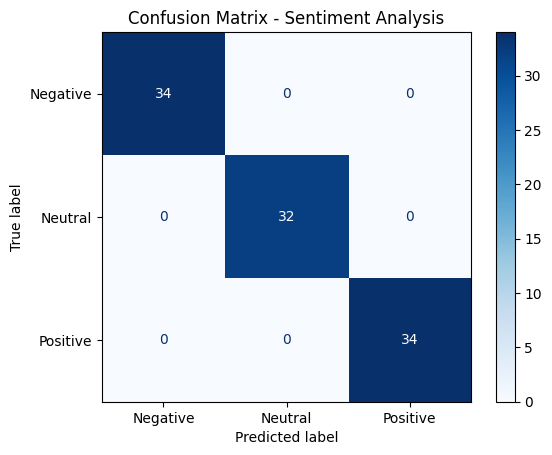


CUSTOM REVIEW PREDICTIONS
-------------------------

Review:
 This movie was amazing and I really enjoyed it.
Predicted Sentiment:
 POSITIVE

Review:
 The film was boring, disappointing, and a waste of time.
Predicted Sentiment:
 NEGATIVE

Review:
 The acting was good but the story was average.
Predicted Sentiment:
 NEUTRAL


In [14]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 2. Load the dataset from the local reviews.csv file we created
try:
    df = pd.read_csv("reviews.csv")
except FileNotFoundError:
    # Fallback to a working online public sentiment dataset url if local file is missing
    url = "https://raw.githubusercontent.com/datasets/sentiment-analysis/master/data/sentiment.csv"
    try:
        df = pd.read_csv(url)
    except Exception as e:
        raise RuntimeError(
            "Dataset loading failed. Please ensure 'reviews.csv' exists or check your internet connection."
        ) from e

# 3. Display dataset information
print("Dataset Shape:", df.shape)
print(df.head())

# 4. Standardize column names and clean missing values
df.columns = df.columns.str.lower().str.strip()

df = df.dropna(subset=["review", "sentiment"])

df["sentiment"] = (
    df["sentiment"].astype(str).str.lower().str.strip()
)

# Keep up to 2000 reviews for faster execution
df = df.head(2000)

X = df["review"].astype(str)
y = df["sentiment"]

# 5. Split dataset into 80% training and 20% testing
# Only stratify if all classes have at least 2 members
class_counts = y.value_counts()
if len(class_counts) > 1 and class_counts.min() >= 2:
    stratify_option = y
else:
    stratify_option = None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=stratify_option
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 6. Convert text into TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 7. Train Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

# 8. Predict test data
y_pred = model.predict(X_test_tfidf)

# 9. Evaluate model
accuracy = accuracy_score(y_test, y_pred)

# Removed 'pos_label' to avoid multi-class metrics warnings
precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("\nMODEL EVALUATION")
print("-------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 10. Display confusion matrix
unique_labels = sorted(list(y.unique()))
cm = confusion_matrix(
    y_test, y_pred,
    labels=unique_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[l.capitalize() for l in unique_labels]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Sentiment Analysis")
plt.show()

# 11. Test with three custom reviews
custom_reviews = [
    "This movie was amazing and I really enjoyed it.",
    "The film was boring, disappointing, and a waste of time.",
    "The acting was good but the story was average."
]

custom_tfidf = tfidf.transform(custom_reviews)
predictions = model.predict(custom_tfidf)

print("\nCUSTOM REVIEW PREDICTIONS")
print("-------------------------")

for review, prediction in zip(custom_reviews, predictions):
    print("\nReview:\n", review)
    print("Predicted Sentiment:\n", prediction.upper())